## Marco 2 — Modelos e Avaliação Comparativa

Disciplina: Aprendizagem de Máquina — ADS033
Curso: Análise e Desenvolvimento de Sistemas — IESB

### Apresentação

Nesta etapa do projeto, foram desenvolvidos e avaliados diferentes algoritmos de aprendizagem de máquina aplicados à classificação de registros relacionados à doença renal crônica (DRC).

O trabalho contempla técnicas de aprendizagem supervisionada e não supervisionada, buscando comparar o desempenho dos modelos, interpretar os resultados e identificar suas limitações.

### Objetivos

* Aplicar o algoritmo K-Means e interpretar os agrupamentos encontrados.
* Desenvolver diferentes modelos de classificação supervisionada.
* Avaliar os modelos utilizando métricas adequadas.
* Aplicar validação cruzada estratificada.
* Comparar os resultados com o modelo baseline desenvolvido no Marco 1.
* Analisar limitações, riscos e possibilidades de aplicação dos modelos.

### 1.1 Recuperação da base de dados

Nesta etapa, realizamos a recuperação da base de dados Chronic Kidney Disease (CKD), disponibilizada pelo UCI Machine Learning Repository e utilizada anteriormente no Marco 1.

O download é realizado diretamente da fonte original, garantindo a continuidade do projeto. Além disso, verificamos a integridade do arquivo por meio do algoritmo SHA-256, comparando seu resultado com o código de verificação da versão utilizada anteriormente. Esse procedimento permite confirmar que estamos trabalhando com a mesma versão da base de dados.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib

ROOT = Path('/content/marco2_doenca_renal')
data_path = ROOT / 'data/ckd_uci.csv'
data_path.parent.mkdir(parents=True, exist_ok=True)

url = 'https://archive.ics.uci.edu/static/public/336/data.csv'

if not data_path.exists():
    urlretrieve(url, data_path)

sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
expected = '0eeea8d17f5ad8792d854999d6ddf1602ec4e116616f6ccdfdaef0ba8109e694'

assert sha256 == expected, 'A integridade da base não foi confirmada.'

print('Base recuperada e validada com sucesso!')
print('Arquivo:', data_path)
print('SHA-256:', sha256)

Base recuperada e validada com sucesso!
Arquivo: /content/marco2_doenca_renal/data/ckd_uci.csv
SHA-256: 0eeea8d17f5ad8792d854999d6ddf1602ec4e116616f6ccdfdaef0ba8109e694


A base de dados foi recuperada corretamente e sua integridade foi confirmada por meio da verificação SHA-256. Isso indica que o arquivo corresponde à mesma versão utilizada no Marco 1.

Com a base disponível, podemos dar continuidade à preparação dos dados e ao desenvolvimento dos modelos de aprendizagem de máquina.

### 1.2 Limpeza e auditoria dos dados

Nesta etapa, realizamos a limpeza e a verificação da base de dados para identificar possíveis inconsistências antes da utilização dos modelos.

Primeiro, criamos uma cópia da base original e removemos espaços desnecessários dos campos de texto. Em seguida, identificamos valores ausentes, representados por ? ou campos vazios, e convertemos os atributos numéricos para seus respectivos formatos.

Também verificamos a variável-alvo, as categorias existentes e a presença de registros duplicados. Os valores ausentes serão mantidos nesta etapa, pois serão tratados posteriormente durante o pré-processamento.

In [2]:
import numpy as np
import pandas as pd

raw = pd.read_csv(data_path, dtype=str)

num = ['age', 'bp', 'bgr', 'bu', 'sc', 'sod', 'pot',
       'hemo', 'pcv', 'wbcc', 'rbcc']

cat = ['sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba',
       'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

target = 'class'

df = raw.copy()
df = df.apply(lambda col: col.str.strip() if col.dtype == 'object' else col)
df = df.replace({'?': np.nan, '': np.nan})

for col in num:
    df[col] = pd.to_numeric(df[col], errors='coerce')

assert set(df[target].dropna().unique()) == {'ckd', 'notckd'}

duplicatas = df.duplicated().sum()
df = df.drop_duplicates().copy()

print('Registros originais:', len(raw))
print('Duplicatas removidas:', duplicatas)
print('Registros finais:', len(df))
print('Valores ausentes:', df.isna().sum().sum())
print('\nDistribuição da variável-alvo:')
print(df[target].value_counts())

Registros originais: 400
Duplicatas removidas: 0
Registros finais: 400
Valores ausentes: 1012

Distribuição da variável-alvo:
class
ckd       250
notckd    150
Name: count, dtype: int64


### Resultado da limpeza e auditoria

A base permaneceu com 400 registros, sem duplicatas, e apresentou 1.012 valores ausentes. A distribuição da variável-alvo foi mantida em 250 registros ckd (62,5%) e 150 notckd (37,5%), os mesmos valores identificados no Marco 1.

Com isso, confirmamos a consistência da base utilizada e damos continuidade à preparação dos dados.

### 1.3 Protocolo experimental
Com o Scikit-learn, foi realizada a divisão da base em três conjuntos, utilizando a função `train_test_split()` em duas etapas. Inicialmente, foram reservados 20% dos registros para teste, mantendo os 80% restantes para desenvolvimento. Em seguida, esse conjunto foi dividido, destinando 75% para treinamento e 25% para validação. Dessa forma, foi obtida a proporção final de 60%, 20% e 20%.

Nas duas divisões, foi utilizada a estratificação (`stratify`), preservando a proporção entre as classes nos diferentes conjuntos. Também foi definido `random_state=42`, permitindo reproduzir a mesma divisão em novas execuções.

Os atributos preditores foram separados da variável-alvo, que foi codificada numericamente, atribuindo 1 à classe `ckd` e 0 à classe `notckd`. Por fim, foram verificadas a independência das partições e a quantidade de registros em cada conjunto. Os índices utilizados também foram salvos para permitir a recuperação da divisão.

In [3]:
from sklearn.model_selection import train_test_split
import json

SEED = 42

X = df[num + cat].copy()
y = df[target].map({'ckd': 1, 'notckd': 0}).astype(int)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev
)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(df)

particoes = {
    'Treinamento': y_train,
    'Validação': y_val,
    'Teste': y_test
}

resumo = pd.DataFrame([
    {
        'Conjunto': nome,
        'Registros': len(rotulos),
        'CKD': int((rotulos == 1).sum()),
        'notCKD': int((rotulos == 0).sum()),
        'CKD (%)': round(rotulos.mean() * 100, 2)
    }
    for nome, rotulos in particoes.items()
])

indices = {
    'semente': SEED,
    'treinamento': [int(i) for i in X_train.index],
    'validacao': [int(i) for i in X_val.index],
    'teste': [int(i) for i in X_test.index]
}

(ROOT / 'indices_particoes.json').write_text(
    json.dumps(indices, indent=4), encoding='utf-8'
)

display(resumo)
print('Nenhum registro foi compartilhado entre os conjuntos.')
print('Divisão concluída com sucesso!')

,Conjunto,Registros,CKD,notCKD,CKD (%)
0,Treinamento,240,150,90,62.5
1,Validação,80,50,30,62.5
2,Teste,80,50,30,62.5


Nenhum registro foi compartilhado entre os conjuntos.
Divisão concluída com sucesso!


 ### Resultado do protocolo experimental
 A base foi dividida em 240 registros para treinamento, 80 para validação e 80 para teste. A estratificação manteve a mesma proporção de classes do Marco 1 nos três conjuntos: 62,5% ckd e 37,5% notckd.

Assim, mantemos o mesmo protocolo experimental para desenvolver e avaliar os modelos.

### 1.4 Pré-processamento dos dados

Com os conjuntos de treinamento, validação e teste definidos, os dados foram preparados para a aplicação dos modelos de aprendizagem de máquina por meio de técnicas de imputação e transformação das variáveis.

Os valores ausentes das variáveis numéricas foram preenchidos pela mediana, enquanto os categóricos foram preenchidos pela moda. Também foi aplicado o RobustScaler às variáveis numéricas e o One-Hot Encoding às categóricas.

O pré-processador foi ajustado somente com os dados de treinamento. Em seguida, as mesmas transformações foram aplicadas aos conjuntos de validação e teste, evitando que informações desses conjuntos influenciassem o ajuste.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num),
    ('cat', cat_pipeline, cat)
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

print('Treinamento:', X_train_prepared.shape)
print('Validação:', X_val_prepared.shape)
print('Teste:', X_test_prepared.shape)

Treinamento: (240, 48)
Validação: (80, 48)
Teste: (80, 48)


### Resultado do pré-processamento

O pré-processamento foi realizado com sucesso, resultando em 48 atributos para cada registro. As dimensões dos conjuntos foram mantidas: 240 registros de treinamento, 80 de validação e 80 de teste.

A transformação dos dados foi concluída sem alterar a quantidade de registros, deixando os conjuntos preparados para a aplicação dos algoritmos de aprendizagem de máquina.

### 2.1 Escolha do número de clusters

Para identificar possíveis agrupamentos nos dados, foi utilizado o algoritmo K-Means sem considerar a variável-alvo `class`.

A quantidade de grupos foi avaliada com valores de K entre 2 e 10, utilizando o método do cotovelo (Elbow Method) e o coeficiente de silhueta (Silhouette Score). Esses indicadores permitiram analisar a compactação e a separação dos agrupamentos.

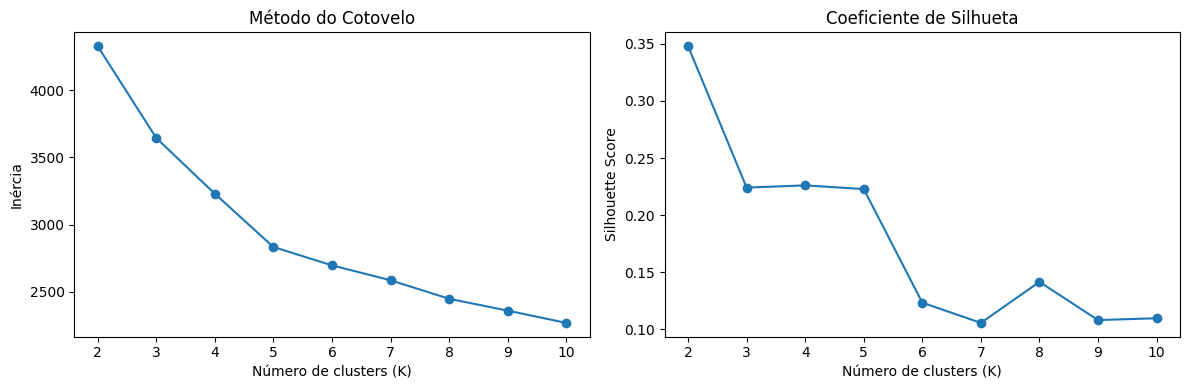

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_kmeans = X_train_prepared

ks = range(2, 11)
inertias = []
silhouettes = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(X_kmeans)

    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_kmeans, labels))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ks, inertias, marker='o')
plt.title('Método do Cotovelo')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inércia')

plt.subplot(1, 2, 2)
plt.plot(ks, silhouettes, marker='o')
plt.title('Coeficiente de Silhueta')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

### Resultado da escolha do número de clusters

No método do cotovelo, observamos uma redução mais acentuada da inércia até aproximadamente K = 5, indicando uma possível concentração dos agrupamentos nesse intervalo, embora o gráfico não apresente um ponto de inflexão totalmente definido.

Já no coeficiente de silhueta, K = 2 apresentou o melhor resultado, aproximadamente 0,35. Esse valor indica uma separação limitada entre os grupos, mas foi superior aos demais valores avaliados.

Considerando os dois indicadores, foi escolhido K = 2, priorizando o melhor resultado do coeficiente de silhueta. Essa configuração foi utilizada na formação dos agrupamentos, considerando também a limitação observada na separação dos dados.

### 2.2 Formação dos clusters

Após a definição de K = 2, o algoritmo K-Means foi aplicado aos dados de treinamento para formar os agrupamentos. Em seguida, os clusters encontrados foram comparados com a classificação original dos registros, permitindo analisar como os grupos se relacionam com as classes ckd e notckd.

A variável `class` não participou da formação dos agrupamentos. Ela foi utilizada somente após a execução do algoritmo, para comparar os resultados obtidos com as classificações originais.

In [6]:
kmeans = KMeans(n_clusters=2, random_state=SEED, n_init=10)
clusters = kmeans.fit_predict(X_kmeans)

resultado = pd.DataFrame({
    'Cluster': clusters,
    'Class': y_train.values
})

print('Distribuição dos clusters:')
print(resultado['Cluster'].value_counts().sort_index())

print('\nClusters e classificação original:')
print(pd.crosstab(resultado['Cluster'], resultado['Class']))

Distribuição dos clusters:
Cluster
0    183
1     57
Name: count, dtype: int64

Clusters e classificação original:
Class     0   1
Cluster        
0        90  93
1         0  57


### Resultado da formação dos clusters

O K-Means distribuiu os 240 registros de treinamento em dois grupos: o Cluster 0, com 183 registros, e o Cluster 1, com 57.

Na comparação com a classificação original, o Cluster 0 reuniu 90 registros notckd e 93 ckd. Já o Cluster 1 agrupou exclusivamente registros ckd, totalizando 57 casos.

Os resultados mostram que um dos grupos apresentou maior concentração de registros classificados como ckd, mas a separação não foi completa, pois o Cluster 0 reuniu registros das duas classes. Portanto, os agrupamentos apresentam uma relação com as classificações originais, mas não representam uma classificação perfeita dos registros.

### 2.3 Visualização dos clusters

Para complementar a análise dos agrupamentos, foi utilizado um gráfico de barras que apresenta a distribuição das classes ckd e notckd em cada cluster. A visualização permite comparar a composição dos grupos e identificar possíveis concentrações de registros de uma mesma classe.

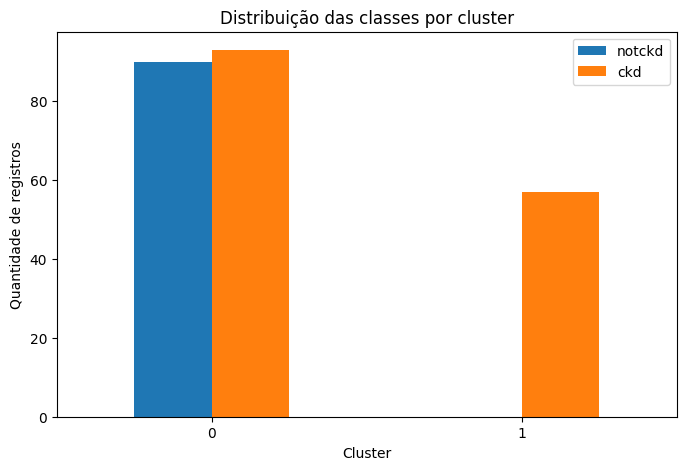

In [7]:
resultado.groupby(['Cluster', 'Class']).size().unstack().plot(
    kind='bar', figsize=(8, 5)
)

plt.title('Distribuição das classes por cluster')
plt.xlabel('Cluster')
plt.ylabel('Quantidade de registros')
plt.xticks(rotation=0)
plt.legend(['notckd', 'ckd'])
plt.show()

### Resultado da visualização dos clusters

O gráfico confirma a distribuição identificada anteriormente. O Cluster 0 apresentou quantidades próximas entre as classes, com 90 registros notckd e 93 ckd. Já o Cluster 1 foi composto exclusivamente por 57 registros ckd.

A visualização reforça que o K-Means identificou um agrupamento com maior concentração de registros ckd, mas não conseguiu separar completamente as duas classes. Isso demonstra que os grupos encontrados possuem relação com a classificação original, embora não substituam um modelo supervisionado.

### 3.1 Treinamento da árvore de decisão

Após a preparação dos dados, foi aplicado o algoritmo de Árvore de Decisão para classificar os registros entre ckd e notckd.

O modelo foi ajustado com os dados de treinamento e avaliado no conjunto de validação. Para analisar seu desempenho, foram utilizadas a acurácia, a precisão, a revocação e o F1-score.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

tree = DecisionTreeClassifier(random_state=SEED)
tree.fit(X_train_prepared, y_train)

train_pred = tree.predict(X_train_prepared)
val_pred = tree.predict(X_val_prepared)

print('Acurácia no treinamento:', accuracy_score(y_train, train_pred))
print('Acurácia na validação:', accuracy_score(y_val, val_pred))

print('\nRelatório de classificação:')
print(classification_report(
    y_val, val_pred,
    target_names=['notckd', 'ckd'],
    zero_division=0
))

Acurácia no treinamento: 1.0
Acurácia na validação: 0.975

Relatório de classificação:
              precision    recall  f1-score   support

      notckd       0.97      0.97      0.97        30
         ckd       0.98      0.98      0.98        50

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80



### Resultado do treinamento da árvore de decisão

A Árvore de Decisão alcançou 100% de acurácia no treinamento e 97,5% na validação. As métricas de precisão, revocação e F1-score ficaram entre 97% e 98% para as duas classes.

A pequena diferença entre os resultados indica que o modelo pode apresentar um leve sobreajuste, pois obteve desempenho superior nos dados utilizados durante o treinamento. Mesmo assim, apresentou excelente resultado no conjunto de validação.

### 3.2 Análise da profundidade da árvore

A profundidade de uma árvore de decisão influencia diretamente sua complexidade. Para avaliar esse comportamento, foram testados valores entre 1 e 10, comparando as taxas de erro nos conjuntos de treinamento e validação.

Essa comparação permite observar como o aumento da profundidade afeta o desempenho do modelo e identificar possíveis sinais de sobreajuste.

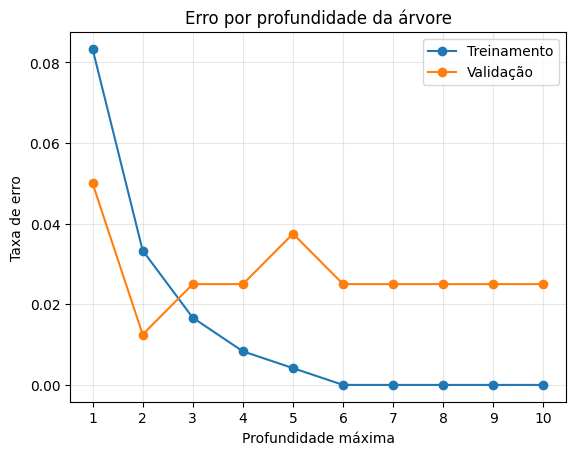

In [9]:
profundidades = range(1, 11)
erro_treino = []
erro_validacao = []

for profundidade in profundidades:
    modelo = DecisionTreeClassifier(
        max_depth=profundidade,
        random_state=SEED
    )

    modelo.fit(X_train_prepared, y_train)

    erro_treino.append(1 - accuracy_score(y_train, modelo.predict(X_train_prepared)))
    erro_validacao.append(1 - accuracy_score(y_val, modelo.predict(X_val_prepared)))

plt.plot(profundidades, erro_treino, marker='o', label='Treinamento')
plt.plot(profundidades, erro_validacao, marker='o', label='Validação')

plt.title('Erro por profundidade da árvore')
plt.xlabel('Profundidade máxima')
plt.ylabel('Taxa de erro')
plt.xticks(list(profundidades))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Resultado da análise da profundidade

O gráfico demonstra que o erro no treinamento diminuiu conforme a profundidade da árvore aumentou, chegando a zero nas maiores profundidades avaliadas.

No conjunto de validação, o menor erro foi observado na profundidade 2, aproximadamente 1,25%. A partir desse ponto, ocorreram pequenas oscilações, indicando que o aumento da complexidade não trouxe melhorias consistentes.

Esse comportamento mostra que árvores mais profundas conseguem se ajustar melhor aos dados de treinamento, mas isso não significa necessariamente um melhor desempenho em novos registros.

### 3.3 Importância das variáveis

Além de analisar a profundidade da árvore, também foi avaliada a importância das variáveis utilizadas pelo modelo. Essa análise permite identificar quais atributos tiveram maior contribuição nas decisões realizadas pela Árvore de Decisão, facilitando a interpretação dos resultados.

,Importância
num__hemo,0.677556
cat__htn_yes,0.104409
num__rbcc,0.081148
cat__sg_1.015,0.050204
num__bu,0.033400
num__pcv,0.022223
num__age,0.017561
num__bgr,0.011852
num__sc,0.001648
num__pot,0.000000


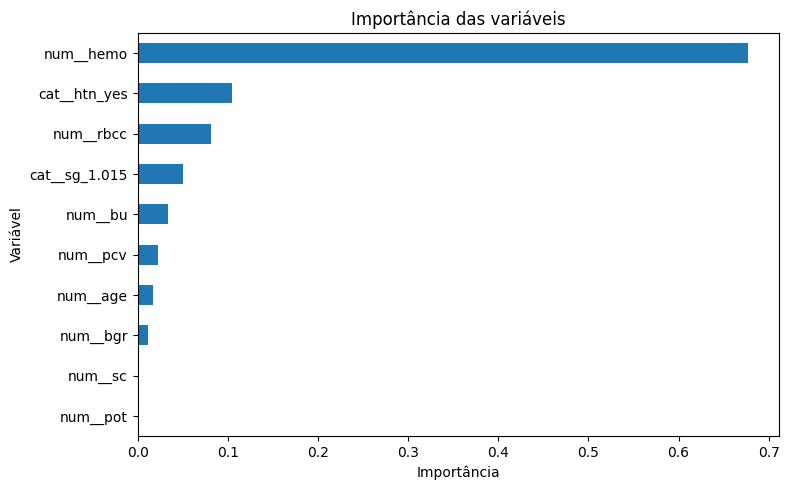

In [19]:
importancias = pd.Series(
    tree.feature_importances_,
    index=preprocessor.get_feature_names_out()
).sort_values(ascending=False).head(10)

display(importancias.to_frame('Importância'))

importancias.sort_values().plot(
    kind='barh', figsize=(8, 5)
)

plt.title('Importância das variáveis')
plt.xlabel('Importância')
plt.ylabel('Variável')
plt.tight_layout()
plt.show()

### Resultado da importância das variáveis

O gráfico mostra que a hemoglobina (`num__hemo`) foi a variável de maior importância para a Árvore de Decisão, com aproximadamente 67,76% da importância total.

Em seguida, destacaram-se a presença de hipertensão (`cat__htn_yes`), com 10,44%, a contagem de hemácias (`num__rbcc`), com 8,11%, e a densidade urinária (`cat__sg_1.015`), com 5,02%.

As demais variáveis apresentaram contribuições menores. A creatinina (`num__sc`), por exemplo, teve importância próxima de zero, enquanto o potássio (`num__pot`) não apresentou contribuição nas decisões da árvore.

Esses resultados mostram que o modelo concentrou grande parte de suas decisões na hemoglobina, utilizando as demais características como informações complementares. É importante destacar que a importância representa a contribuição das variáveis para as decisões desse modelo, não indicando necessariamente uma relação de causa e efeito com a doença.

### 3.4 Extração e interpretação das regras

Para compreender melhor as decisões realizadas pela Árvore de Decisão, foram extraídas três regras diretamente da estrutura do modelo.

Cada regra representa um caminho percorrido dentro da árvore, combinando condições relacionadas às características dos registros até chegar a uma classificação. Essa análise permite observar quais combinações de atributos influenciaram as decisões do algoritmo.

In [21]:
import numpy as np

arvore = tree.tree_
nomes = preprocessor.get_feature_names_out()
scaler = preprocessor.named_transformers_['num'].named_steps['scaler']

descricoes = {
    'hemo': 'Hemoglobina',
    'rbcc': 'Contagem de hemácias',
    'pcv': 'Hematócrito',
    'bu': 'Ureia sanguínea',
    'bgr': 'Glicose sanguínea',
    'sc': 'Creatinina sérica'
}

regras = []

def extrair(no, condicoes):
    if arvore.children_left[no] == arvore.children_right[no]:
        classe = 'CKD' if np.argmax(arvore.value[no]) == 1 else 'Sem CKD'
        regras.append((condicoes, classe))
        return

    nome = nomes[arvore.feature[no]]
    limite = arvore.threshold[no]

    if nome.startswith('num__'):
        coluna = nome.split('__')[1]
        indice = num.index(coluna)
        limite = limite * scaler.scale_[indice] + scaler.center_[indice]
        nome = descricoes.get(coluna, coluna)

    extrair(arvore.children_left[no], condicoes + [f'{nome} <= {limite:.2f}'])
    extrair(arvore.children_right[no], condicoes + [f'{nome} > {limite:.2f}'])

extrair(0, [])

for i, (condicoes, classe) in enumerate(regras[:3], 1):
    print(f'\nREGRA {i}')

    for condicao in condicoes:
        print(f'  {condicao}')

    print(f'Classificação: {classe}')
    print('-' * 40)


REGRA 1
  Hemoglobina <= 13.23
  Contagem de hemácias <= 5.08
  Hematócrito <= 40.50
  Ureia sanguínea <= 16.51
  Glicose sanguínea <= 112.04
Classificação: CKD
----------------------------------------

REGRA 2
  Hemoglobina <= 13.23
  Contagem de hemácias <= 5.08
  Hematócrito <= 40.50
  Ureia sanguínea <= 16.51
  Glicose sanguínea > 112.04
Classificação: Sem CKD
----------------------------------------

REGRA 3
  Hemoglobina <= 13.23
  Contagem de hemácias <= 5.08
  Hematócrito <= 40.50
  Ureia sanguínea > 16.51
  Creatinina sérica <= 0.84
  Ureia sanguínea <= 34.16
Classificação: CKD
----------------------------------------


### Resultado da extração e interpretação das regras

As regras extraídas mostram como a Árvore de Decisão combina diferentes características dos registros para chegar a uma classificação. Com a conversão dos limites para a escala original, foi possível interpretar melhor as condições utilizadas pelo modelo.

- **Regra 1:** registros com hemoglobina de até 13,23, contagem de hemácias de até 5,08, hematócrito de até 40,50, ureia de até 16,51 e glicose sanguínea de até 112,04 foram classificados como CKD.
- **Regra 2:** manteve as mesmas condições da primeira regra, mas, quando a glicose sanguínea ultrapassou 112,04, a classificação resultante foi Sem CKD.
- **Regra 3:** combinou hemoglobina de até 13,23, contagem de hemácias de até 5,08, hematócrito de até 40,50, ureia acima de 16,51 e até 34,16 e creatinina sérica de até 0,84, resultando na classificação CKD.

As regras demonstram como diferentes combinações de características influenciaram as decisões do modelo. Esses limites representam critérios aprendidos pela árvore a partir dos dados, não valores de referência médica nem critérios suficientes para estabelecer um diagnóstico.

### 4.1 Treinamento e avaliação do KNN

Após a análise da Árvore de Decisão, foi aplicado o algoritmo K-Nearest Neighbors (KNN), que realiza classificações considerando a proximidade entre os registros. O modelo utiliza a distância entre as características para identificar os vizinhos mais próximos e determinar a classe de um novo registro.

Foi definido o valor de cinco vizinhos (`n_neighbors=5`). O modelo foi treinado com os dados preparados e avaliado nos conjuntos de treinamento e validação, utilizando a acurácia, a precisão, a revocação e o F1-score.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_prepared, y_train)

train_pred = knn.predict(X_train_prepared)
val_pred = knn.predict(X_val_prepared)

print('Acurácia no treinamento:', accuracy_score(y_train, train_pred))
print('Acurácia na validação:', accuracy_score(y_val, val_pred))

print('\nRelatório de classificação:')
print(classification_report(
    y_val, val_pred,
    target_names=['notckd', 'ckd'],
    zero_division=0
))

Acurácia no treinamento: 0.9583333333333334
Acurácia na validação: 0.9625

Relatório de classificação:
              precision    recall  f1-score   support

      notckd       0.91      1.00      0.95        30
         ckd       1.00      0.94      0.97        50

    accuracy                           0.96        80
   macro avg       0.95      0.97      0.96        80
weighted avg       0.97      0.96      0.96        80



### Resultado do treinamento e avaliação do KNN

O KNN alcançou 95,83% de acurácia no treinamento e 96,25% na validação, apresentando resultados próximos entre os dois conjuntos.

Na classe notckd, o modelo obteve 91% de precisão e 100% de revocação, identificando todos os registros dessa classe. Já na classe ckd, alcançou 100% de precisão e 94% de revocação, demonstrando que todos os registros classificados como CKD estavam corretos, embora alguns casos dessa classe não tenham sido identificados.

A acurácia de 96,25% indica que 77 dos 80 registros de validação foram classificados corretamente? Não: foram 77 registros se arredondado? A acurácia exata de 96,25% corresponde a 77 acertos em 80 registros.

A proximidade entre os resultados de treinamento e validação indica um comportamento consistente do modelo nessa avaliação.

### 5.1 Treinamento e avaliação do Naive Bayes

Dando continuidade à comparação dos modelos supervisionados, foi aplicado o algoritmo Naive Bayes, que utiliza conceitos de probabilidade para estimar a classe de cada registro com base em suas características.

O modelo considera a hipótese de independência condicional entre os atributos, ou seja, assume que as características são independentes entre si quando a classe é conhecida. Foi utilizada a implementação GaussianNB, que também considera uma distribuição normal para os valores de cada atributo dentro das classes.

O modelo foi treinado com os dados preparados e avaliado nos conjuntos de treinamento e validação, utilizando as mesmas métricas dos algoritmos anteriores.

In [12]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_prepared, y_train)

train_pred = nb.predict(X_train_prepared)
val_pred = nb.predict(X_val_prepared)

print('Acurácia no treinamento:', accuracy_score(y_train, train_pred))
print('Acurácia na validação:', accuracy_score(y_val, val_pred))

print('\nRelatório de classificação:')
print(classification_report(
    y_val, val_pred,
    target_names=['notckd', 'ckd'],
    zero_division=0
))

Acurácia no treinamento: 0.9833333333333333
Acurácia na validação: 1.0

Relatório de classificação:
              precision    recall  f1-score   support

      notckd       1.00      1.00      1.00        30
         ckd       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



### Resultado do treinamento e avaliação do Naive Bayes

O Naive Bayes alcançou 98,33% de acurácia no treinamento e 100% na validação. O modelo apresentou 100% de precisão, revocação e F1-score para as classes notckd e ckd.

Isso significa que os 80 registros do conjunto de validação foram classificados corretamente, sem erros nessa avaliação.

Apesar do resultado, é importante considerar que o desempenho observado corresponde a uma divisão específica dos dados. Por isso, a validação cruzada e a avaliação no conjunto de teste serão importantes para verificar se o modelo mantém esse desempenho em outros registros.

### 6.1 Treinamento e avaliação da Rede Neural (MLP)

Após a avaliação dos modelos anteriores, foi aplicada uma rede neural do tipo Multilayer Perceptron (MLP), capaz de identificar padrões nos dados por meio de camadas de neurônios interconectadas.

O modelo foi configurado com duas camadas ocultas, contendo 64 e 32 neurônios, respectivamente, e limite de 300 iterações. Também foi utilizado o recurso de parada antecipada (`early_stopping=True`), que interrompe o treinamento quando não são observadas melhorias no desempenho da validação interna.

A rede foi treinada com os dados preparados e avaliada no conjunto de validação, permitindo comparar seu desempenho com os algoritmos anteriores.

In [13]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=300,
    early_stopping=True,
    random_state=SEED
)

mlp.fit(X_train_prepared, y_train)

train_pred = mlp.predict(X_train_prepared)
val_pred = mlp.predict(X_val_prepared)

print('Acurácia no treinamento:', accuracy_score(y_train, train_pred))
print('Acurácia na validação:', accuracy_score(y_val, val_pred))

print('\nRelatório de classificação:')
print(classification_report(
    y_val, val_pred,
    target_names=['notckd', 'ckd'],
    zero_division=0
))

Acurácia no treinamento: 0.9583333333333334
Acurácia na validação: 0.9125

Relatório de classificação:
              precision    recall  f1-score   support

      notckd       0.93      0.83      0.88        30
         ckd       0.91      0.96      0.93        50

    accuracy                           0.91        80
   macro avg       0.92      0.90      0.90        80
weighted avg       0.91      0.91      0.91        80



### Resultado do treinamento e avaliação da Rede Neural

A rede neural alcançou 95,83% de acurácia no treinamento e 91,25% na validação, apresentando uma diferença de aproximadamente 4,58 pontos percentuais entre os conjuntos.

Na classe notckd, o modelo obteve 93% de precisão e 83% de revocação, demonstrando que alguns registros sem a doença não foram identificados corretamente. Já na classe ckd, alcançou 91% de precisão e 96% de revocação, identificando a maioria dos registros dessa classe.

A acurácia geral de 91,25% indica que 73 dos 80 registros de validação foram classificados corretamente. Apesar do desempenho satisfatório, a rede neural apresentou resultados inferiores aos obtidos pelo KNN e pelo Naive Bayes nessa avaliação.

### 6.2 Curvas de perda e acurácia

Para complementar a avaliação da rede neural, foram analisadas as curvas de perda e acurácia ao longo das épocas de treinamento. Esses gráficos permitem acompanhar a evolução do aprendizado e observar possíveis sinais de subajuste ou sobreajuste, além de verificar como o modelo se comportou durante o treinamento.

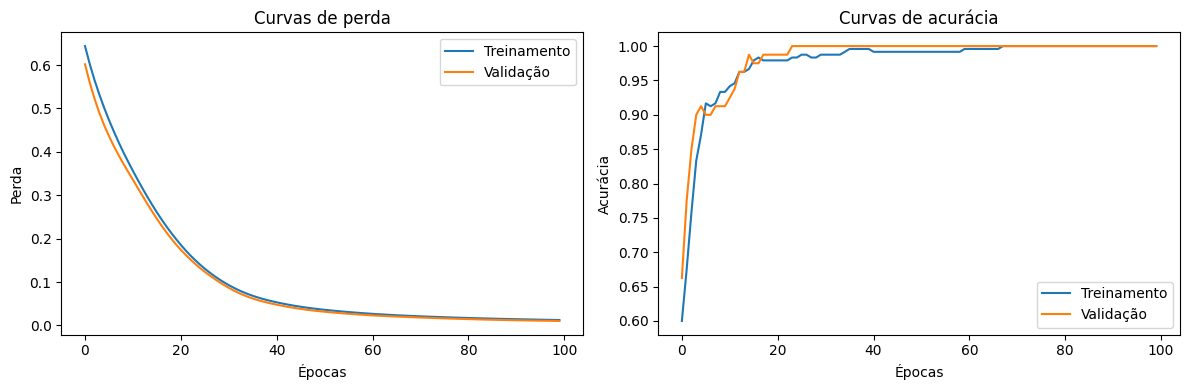

In [20]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss
import matplotlib.pyplot as plt

EPOCAS = 100

mlp_curvas = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=1,
    random_state=SEED
)

perda_treino, perda_val = [], []
acc_treino, acc_val = [], []

for epoca in range(EPOCAS):
    mlp_curvas.partial_fit(
        X_train_prepared, y_train,
        classes=[0, 1] if epoca == 0 else None
    )

    prob_treino = mlp_curvas.predict_proba(X_train_prepared)
    prob_val = mlp_curvas.predict_proba(X_val_prepared)

    perda_treino.append(log_loss(y_train, prob_treino, labels=[0, 1]))
    perda_val.append(log_loss(y_val, prob_val, labels=[0, 1]))

    acc_treino.append(accuracy_score(y_train, mlp_curvas.predict(X_train_prepared)))
    acc_val.append(accuracy_score(y_val, mlp_curvas.predict(X_val_prepared)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(perda_treino, label='Treinamento')
ax[0].plot(perda_val, label='Validação')
ax[0].set_title('Curvas de perda')
ax[0].set_xlabel('Épocas')
ax[0].set_ylabel('Perda')
ax[0].legend()

ax[1].plot(acc_treino, label='Treinamento')
ax[1].plot(acc_val, label='Validação')
ax[1].set_title('Curvas de acurácia')
ax[1].set_xlabel('Épocas')
ax[1].set_ylabel('Acurácia')
ax[1].legend()

plt.tight_layout()
plt.show()

### Resultado da análise das curvas de perda e acurácia

As curvas de perda apresentaram uma redução contínua tanto no treinamento quanto na validação, indicando que o erro diminuiu ao longo das 100 épocas.

As curvas de acurácia também demonstraram uma evolução positiva. Ambos os conjuntos começaram com resultados próximos de 60% e alcançaram 100% ao final do treinamento.

A proximidade entre as curvas indica que, nessa execução, não houve uma diferença expressiva entre o desempenho no treinamento e na validação. Também não foram observados sinais visuais fortes de sobreajuste ou subajuste.

É importante destacar que essa análise foi realizada com uma execução separada da rede neural, utilizando treinamento por 100 épocas. Na avaliação anterior da MLP com parada antecipada, a acurácia na validação foi de 91,25%. Portanto, os resultados dos gráficos devem ser interpretados como uma análise complementar do comportamento de aprendizagem da rede.

### 7.1 Validação cruzada estratificada

Após a avaliação individual dos modelos, foi realizada uma validação cruzada estratificada com cinco divisões, utilizando o método Stratified K-Fold. Esse procedimento permite avaliar os algoritmos em diferentes partições dos dados, mantendo a proporção entre as classes em cada divisão.

Também foi incluído um modelo de referência (Baseline), configurado para classificar todos os registros de acordo com a classe mais frequente. Dessa forma, foi possível comparar os modelos desenvolvidos com uma classificação simples e verificar se realmente conseguiram aprender padrões relevantes nos dados.

A validação cruzada foi realizada somente com os dados de treinamento, mantendo os conjuntos de validação e teste separados.

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Árvore de decisão': DecisionTreeClassifier(random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Rede Neural': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=300,
        early_stopping=True,
        random_state=SEED
    )
}

for nome, modelo in modelos.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('modelo', modelo)
    ])

    resultado = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        scoring=['accuracy', 'f1_macro']
    )

    print(f'\n{nome}')
    print(f"Acurácia: {resultado['test_accuracy'].mean():.3f} ± {resultado['test_accuracy'].std():.3f}")
    print(f"F1-score: {resultado['test_f1_macro'].mean():.3f} ± {resultado['test_f1_macro'].std():.3f}")


Baseline
Acurácia: 0.625 ± 0.000
F1-score: 0.385 ± 0.000

Árvore de decisão
Acurácia: 0.963 ± 0.016
F1-score: 0.959 ± 0.017

KNN
Acurácia: 0.942 ± 0.016
F1-score: 0.940 ± 0.016

Naive Bayes
Acurácia: 0.983 ± 0.008
F1-score: 0.982 ± 0.009

Rede Neural
Acurácia: 0.921 ± 0.053
F1-score: 0.916 ± 0.057


### Resultado da validação cruzada

O Baseline apresentou 62,5% de acurácia e F1-score macro de 0,385. Como utiliza a classe mais frequente, classificou todos os registros como ckd, não conseguindo identificar corretamente os registros notckd.

Os demais modelos apresentaram resultados superiores ao Baseline, demonstrando maior capacidade de diferenciar as duas classes. Entre eles, o Naive Bayes obteve os melhores resultados, com 98,3% de acurácia média e F1-score macro de 0,982.

Além do desempenho superior, o Naive Bayes apresentou baixa variação entre as cinco divisões, indicando maior estabilidade em comparação aos demais modelos supervisionados avaliados.

### 7.2 Comparação geral dos modelos

Com os resultados das avaliações individuais e da validação cruzada, foi elaborada uma comparação geral dos modelos. Foram considerados a acurácia obtida no conjunto de validação, a acurácia média na validação cruzada e o F1-score macro, permitindo analisar o desempenho dos algoritmos sob diferentes critérios.

In [16]:
comparacao = pd.DataFrame({
    'Modelo': ['Baseline', 'Árvore de decisão', 'KNN', 'Naive Bayes', 'Rede Neural'],
    'Acurácia (validação)': [0.625, 0.975, 0.9625, 1.000, 0.9125],
    'Acurácia (CV)': [0.625, 0.963, 0.942, 0.983, 0.921],
    'F1-score (CV)': [0.385, 0.959, 0.940, 0.982, 0.916]
})

print(comparacao.to_string(index=False))

           Modelo  Acurácia (validação)  Acurácia (CV)  F1-score (CV)
         Baseline                0.6250          0.625          0.385
Árvore de decisão                0.9750          0.963          0.959
              KNN                0.9625          0.942          0.940
      Naive Bayes                1.0000          0.983          0.982
      Rede Neural                0.9125          0.921          0.916


### Resultado da comparação geral dos modelos

A comparação evidenciou diferenças no desempenho dos algoritmos avaliados.

O Baseline apresentou o menor resultado, com 62,5% de acurácia, servindo como referência para os demais modelos. A Árvore de Decisão alcançou 97,5% de acurácia na validação e 96,3% na validação cruzada, enquanto o KNN obteve 96,25% e 94,2%, respectivamente.

O Naive Bayes apresentou o melhor desempenho, alcançando 100% de acurácia na validação, 98,3% na validação cruzada e F1-score macro de 0,982. Já a Rede Neural registrou 91,25% de acurácia na validação e 92,1% na validação cruzada.

Considerando os indicadores analisados, o Naive Bayes se destacou por apresentar os maiores valores de acurácia e F1-score, além de baixa variação entre as divisões da validação cruzada. Por esses motivos, foi selecionado para a avaliação final no conjunto de teste.

### 7.3 Escolha e justificativa do modelo

Com base nos resultados obtidos, o Naive Bayes foi selecionado como o modelo de melhor desempenho geral. A escolha considerou sua acurácia de 100% na validação, 98,3% na validação cruzada e F1-score macro de 0,982, além da baixa variação entre as divisões.

Entre os modelos avaliados, ele apresentou a melhor combinação de desempenho e estabilidade, sendo o principal candidato para uma possível aplicação futura. Entretanto, sua utilização em produção clínica ainda exigiria testes com bases externas, avaliação de possíveis vieses e validação por profissionais da área da saúde. Portanto, o resultado obtido representa o melhor desempenho experimental do projeto, não uma autorização para utilização como ferramenta de diagnóstico.

### 8.1 Avaliação final no conjunto de teste

Após a seleção do Naive Bayes, o modelo foi treinado novamente utilizando os dados de desenvolvimento, que reúnem os conjuntos de treinamento e validação. Para isso, o pré-processamento também foi ajustado com esses dados, mantendo o conjunto de teste separado.

Em seguida, o modelo foi avaliado nos registros do conjunto de teste, que não haviam participado das etapas anteriores de treinamento e seleção. Essa avaliação permitiu verificar seu desempenho diante de dados reservados para a análise final.8.1 Avaliação final no conjunto de teste

Nesta etapa, vamos treinar novamente o Naive Bayes utilizando os dados de desenvolvimento, que reúnem os conjuntos de treinamento e validação. Em seguida, o modelo será avaliado no conjunto de teste, que permaneceu separado durante as etapas anteriores.

Essa avaliação permite verificar se o desempenho observado anteriormente se mantém diante de dados que ainda não foram utilizados pelo modelo.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB

modelo_final = Pipeline([
    ('preprocessor', preprocessor),
    ('modelo', GaussianNB())
])

modelo_final.fit(X_dev, y_dev)
test_pred = modelo_final.predict(X_test)

print('Acurácia no teste:', accuracy_score(y_test, test_pred))

print('\nRelatório de classificação:')
print(classification_report(
    y_test, test_pred,
    target_names=['notckd', 'ckd'],
    zero_division=0
))

Acurácia no teste: 1.0

Relatório de classificação:
              precision    recall  f1-score   support

      notckd       1.00      1.00      1.00        30
         ckd       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



### Resultado da avaliação final no conjunto de teste

O Naive Bayes alcançou 100% de acurácia no conjunto de teste, classificando corretamente os 80 registros avaliados. As métricas de precisão, revocação e F1-score também foram de 100% para as classes ckd e notckd.

Esse resultado demonstra que o modelo manteve o desempenho observado nas avaliações anteriores, mesmo diante de registros que não participaram do treinamento ou da seleção do algoritmo.

Entretanto, o resultado corresponde a um conjunto de teste específico, com apenas 80 registros. Portanto, não garante que o mesmo desempenho será obtido em outros conjuntos de dados ou em situações reais.

### 8.2 Limitações e riscos

Apesar dos resultados obtidos, existem limitações que precisam ser consideradas. A base utilizada possui apenas 400 registros e apresenta uma distribuição de 62,5% para a classe ckd e 37,5% para notckd, o que pode influenciar o comportamento dos modelos. Além disso, os dados representam um conjunto específico de pacientes, não garantindo a mesma eficiência em outras populações.

Também é importante considerar as consequências dos erros de classificação. Um falso negativo ocorre quando um registro com CKD é classificado como notckd, podendo levar à falsa impressão de ausência da doença e atrasar uma avaliação adequada. Já um falso positivo ocorre quando um registro notckd é classificado como CKD, podendo gerar preocupação e exames desnecessários.

Dessa forma, mesmo com o desempenho de 100% obtido pelo Naive Bayes no conjunto de teste, o modelo deve ser considerado apenas experimental. Sua utilização em contextos clínicos exigiria avaliações com bases externas, análise de possíveis vieses e validação por profissionais da saúde.

### 9. Considerações finais

O Marco 2 deu continuidade ao trabalho iniciado no Marco 1, ampliando a análise da base de dados e a aplicação de diferentes algoritmos de aprendizagem de máquina, utilizando Python para preparar os dados, treinar modelos e avaliar resultados.

Entre os modelos testados, o Naive Bayes apresentou o melhor desempenho, alcançando 98,3% de acurácia na validação cruzada e 100% nos conjuntos de validação e teste.

Apesar dos resultados, a base possui apenas 400 registros, sendo necessárias avaliações adicionais antes de qualquer aplicação em contexto clínico. O projeto permitiu consolidar os conhecimentos do Marco 1 e ampliar a experiência prática com Python e aprendizagem de máquina.